# Predicting gene expression after genetic perturbation

We compare **Frozen EFM + GEARS** with **Partial Fine-tuning EFM + GEARS**, which trains the last two EFM blocks. Both use cell-specific per-gene contextual embeddings, the same GEARS decoder and the same condition split. SFM supplies gene orders in evaluation mode; EFM gene states are restored to the expression gene order before decoding.

The tutorial uses the original supplied Norman K562 dataset, including its normalized log expression, raw counts and GEARS DE rankings. We preserve the source expression scale throughout preparation. Cells are unpaired observations, so evaluation compares condition means.


## 1. Set up the tutorial

Install the optional graph dependencies with `pip install -e ".[perturbation]"`. Model assets live in `assets/`; the original Norman source and reference GO graph live in `tutorial_data/gene_perturbation_prediction/`. Preparation and fitting operate in memory; the downloaded data file is not modified. Figures remain inline.


In [1]:
from pathlib import Path
import json
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from sccafm import (
    GenePerturbationPredictor,
    build_perturbation_graphs,
    evaluate_gene_perturbation,
    rank_perturbation_response_genes,
    prepare_gene_perturbation_data,
    load_vocab_json,
    resolve_model_assets,
)

warnings.filterwarnings("ignore", message="Mismatch dtype between input and weight")
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "docs":
    REPO_ROOT = REPO_ROOT.parent
MODEL_SOURCE = REPO_ROOT / "assets"
DATA_DIR = REPO_ROOT / "tutorial_data" / "gene_perturbation_prediction"
assets = resolve_model_assets(MODEL_SOURCE)
vocabulary = load_vocab_json(assets.vocab)

MAX_LENGTH = 2048
FROZEN_LAYERS = 12
PARTIAL_FREEZE_LAYERS = 10
EPOCHS = 10
EARLY_STOPPING_PATIENCE = 4
LEARNING_RATE = 3e-4
BACKBONE_LEARNING_RATE = 3e-6
LR_STEP_SIZE = 3
LR_GAMMA = 0.5
BATCH_SIZE = 32
MODEL_SEED = 0
SAMPLING_SEED = 1
plt.rcParams["font.family"] = "Arial"
print("Tutorial assets and reference settings are ready.")


Tutorial assets and reference settings are ready.


## 2. Examine the Norman data

The file is an unchanged copy of the supplied `norman_perturb.h5ad`, with **91,205 cells × 5,045 genes**. It contains normalized log expression in `X`, raw counts in `layers["counts"]`, perturbation labels in `obs["condition"]`, K562 in `obs["cell_type"]`, Ensembl IDs in `var_names` and symbols in `var["gene_name"]`. The source GEARS condition fields and DE caches are retained.

### Prepare your own data

Provide normalized log expression in `adata.X` with the same cell/gene annotation fields. For raw data, normalize the full expression matrix before selecting genes, then apply `log1p`. Compute condition-wise DE rankings against matched controls with a t-test and `rankby_abs=True`, storing gene IDs in `uns["rank_genes_groups_cov_all"]` under the GEARS condition names.

This source has already been normalized and gene-filtered. Its retained raw counts do not contain the full original library sizes, so we do not normalize them again. Source provenance and checksums are recorded in the dataset README and manifest. Prediction inputs must be unperturbed controls.


In [2]:
source = sc.read_h5ad(DATA_DIR / "norman.h5ad")
go_prior = json.loads((DATA_DIR / "go_prior.json").read_text())
dataset_overview = pd.DataFrame([{
    "Dataset": "Norman",
    "Cell type": "K562",
    "Cells": source.n_obs,
    "Measured genes": source.n_vars,
    "Perturbation labels": source.obs["condition"].nunique() - 1,
}])
display(dataset_overview)
display(source.obs[["condition", "cell_type"]].head())
display(source.var[["gene_name"]].head())


,Dataset,Cell type,Cells,Measured genes,Perturbation labels
0,Norman,K562,91205,5045,283


,condition,cell_type
cell_barcode,,
AAACCTGAGGCATGTG-1,TSC22D1+ctrl,K562
AAACCTGAGGCCCTTG-1,KLF1+MAP2K6,K562
AAACCTGCACGAAGCA-1,ctrl,K562
AAACCTGCAGACGTAG-1,CEBPE+RUNX1T1,K562
AAACCTGCAGCCTTGG-1,MAML2+ctrl,K562


,gene_name
gene_id,
ENSG00000239945,RP11-34P13.8
ENSG00000223764,RP11-54O7.3
ENSG00000187634,SAMD11
ENSG00000187642,PERM1
ENSG00000188290,HES4


## 3. Prepare training, validation and test inputs

We use the source `X` directly, preserving its normalized log-expression scale. The preparation helper excludes ontology-unsupported interventions and retains all 102 supported targets plus training-control HVGs in a **2,047-gene EFM panel**. Raw counts are retained on the same selected axes.

The seed-1 reference simulation split assigns 75% of intervention genes and eligible seen-gene combinations to outer training, followed by a 90%/90% nested split for validation. All controls belong to training. This gives **49,849 training cells** (42,496 perturbed and 7,353 controls), **10,754 validation cells**, and **28,754 test cells**. There are 138 training, 31 validation and 107 test perturbation labels. Original labels such as `GENE+ctrl` and `ctrl+GENE` remain separate.

The helper derives GEARS observation fields and fixes one control input per response cell; controls pair with themselves. The GO prior contains **9,853 nodes and 202,314 directed edges**, retaining the reference top 21 incoming rows per target. No co-expression graph is constructed.

We attach the original source DE rankings, filter them to the selected gene panel and take the first 20 retained genes per condition. Validation DE20 selects checkpoints; test DE20 is used only for scoring. Outcome expression and DE rankings are not EFM prediction features.


In [3]:
adata = prepare_gene_perturbation_data(
    source, vocabulary,
    perturbation_genes=go_prior["perturbation_genes"],
    n_genes=2047, cell_type="K562", random_state=1,
)
adata.uns["rank_genes_groups_cov_all"] = source.uns["rank_genes_groups_cov_all"]

train = adata[adata.obs["split"] == "train"].copy()
validation = adata[adata.obs["split"] == "val"].copy()
test = adata[adata.obs["split"] == "test"].copy()
controls = train[train.obs["condition"] == "ctrl"].copy()
test_conditions = adata.uns["perturbation_split"]["conditions"]["test"]

go_edges = pd.read_csv(DATA_DIR / "go_edges.csv", float_precision="round_trip")
graphs = build_perturbation_graphs(
    adata, go_prior["perturbation_genes"], go_edges, top_k=20,
)
control_mean = np.asarray(controls.X.mean(axis=0)).ravel()
display(
    adata.obs.groupby(["split", "evaluation_group"], observed=True)
    .agg(n_cells=("condition", "size"), n_conditions=("condition", "nunique"))
)
display(adata.var[["source_gene_symbol", "gene_symbol", "perturbation_target"]].head())
print(f"Prepared matrix: {adata.n_obs:,} cells × {adata.n_vars:,} genes")
print(f"Control pool: {controls.n_obs:,}")
print(f"GO nodes: {len(graphs.perturbation_genes):,}; GO edges: {graphs.ontology_edges.shape[1]:,}")


n_cells  n_conditions
split evaluation_group                       
test  combo_seen0          1195             9
      combo_seen1         10056            43
      combo_seen2          6686            19
      unseen_single       10817            36
train control              7353             1
      train               42496           138
val   combo_seen1          4276            13
      combo_seen2          1188             5
      unseen_single        5290            13

,source_gene_symbol,gene_symbol,perturbation_target
gene_id,,,
ENSG00000106546,AHR,AHR,True
ENSG00000117713,ARID1A,ARID1A,True
ENSG00000113369,ARRDC3,ARRDC3,True
ENSG00000198513,ATL1,ATL1,True
ENSG00000030110,BAK1,BAK1,True


Prepared matrix: 89,357 cells × 2,047 genes
Control pool: 7,353
GO nodes: 9,853; GO edges: 202,314


## 4. Compare frozen and partial fine-tuning

Both settings start independently from the same pretrained EFM and use FA4 with cell-specific contextual gene embeddings:

- **Frozen EFM + GEARS:** `freeze_layers=12` freezes the complete EFM; the projection and GEARS decoder train.
- **Partial Fine-tuning EFM + GEARS:** `freeze_layers=10` trains the last two EFM blocks, final normalization, projection and decoder. The frozen prefix is cached. SFM remains frozen in both settings.

Both use 2,048 tokens, batch size 32 and at most 10 epochs. Adam uses decoder learning rate 0.0003, trainable EFM learning rate 0.000003 and weight decay 0.0005. Learning rates halve every three epochs. Training stops after four consecutive epochs without a lower validation DE20 MSE. The reference condition-balanced loss combines fourth-power expression error with a sign-direction term weighted by 0.1.

The checkpoint with the lowest validation condition-mean DE20 MSE is used for testing. These settings reduce the initial update size and avoid spending many epochs after validation has stopped improving. They are a prespecified training choice, not a test-set hyperparameter search. Each fitting cell displays a compact training-loss history, followed by a shared checkpoint summary. Full histories remain available through `history_`.


In [4]:
frozen = GenePerturbationPredictor.from_pretrained(
    MODEL_SOURCE, device="cuda", attention_backend="fa4",
    max_length=MAX_LENGTH, hidden_size=64,
)
frozen.fit(
    train, validation_adata=validation, graphs=graphs,
    freeze_layers=FROZEN_LAYERS,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    evaluation_batch_size=128, ordering_batch_size=32,
    learning_rate=LEARNING_RATE, backbone_learning_rate=BACKBONE_LEARNING_RATE,
    weight_decay=5e-4, lr_step_size=LR_STEP_SIZE, lr_gamma=LR_GAMMA,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    direction_weight=0.1, random_state=MODEL_SEED, verbose=False,
)

display(
    pd.DataFrame(frozen.history_)[["epoch", "loss"]]
    .rename(columns={"loss": "train_loss"})
    .set_index("epoch")
    .style.format({"train_loss": "{:.4f}"})
)
print(f"Completed {len(frozen.history_)} epochs; freeze_layers={FROZEN_LAYERS}.")


,train_loss
epoch,
1,0.4673
2,0.4186
3,0.3927
4,0.3875
5,0.3885
6,0.3885
7,0.3868


Completed 7 epochs; freeze_layers=12.


In [5]:
frozen.model.to("cpu")
frozen.ordering_model.to("cpu")
frozen.head.to("cpu")

partial = GenePerturbationPredictor.from_pretrained(
    MODEL_SOURCE, device="cuda", attention_backend="fa4",
    max_length=MAX_LENGTH, hidden_size=64,
)
partial.fit(
    train, validation_adata=validation, graphs=graphs,
    freeze_layers=PARTIAL_FREEZE_LAYERS, cache_frozen_prefix=True,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    evaluation_batch_size=128, ordering_batch_size=32,
    learning_rate=LEARNING_RATE, backbone_learning_rate=BACKBONE_LEARNING_RATE,
    weight_decay=5e-4, lr_step_size=LR_STEP_SIZE, lr_gamma=LR_GAMMA,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    direction_weight=0.1, random_state=MODEL_SEED, verbose=False,
)

display(
    pd.DataFrame(partial.history_)[["epoch", "loss"]]
    .rename(columns={"loss": "train_loss"})
    .set_index("epoch")
    .style.format({"train_loss": "{:.4f}"})
)
print(f"Completed {len(partial.history_)} epochs; freeze_layers={PARTIAL_FREEZE_LAYERS}.")


,train_loss
epoch,
1,0.4679
2,0.4124
3,0.3883
4,0.3870
5,0.3879
6,0.3883
7,0.3869


Completed 7 epochs; freeze_layers=10.


In [6]:
methods = {
    "Frozen EFM + GEARS": frozen,
    "Partial Fine-tuning EFM + GEARS": partial,
}
checkpoint_summary = pd.DataFrame([
    {
        "Setting": name,
        "Selected epoch": model.best_epoch_,
        "Validation DE20 MSE": model.best_validation_mse_de_,
    }
    for name, model in methods.items()
]).set_index("Setting")
display(checkpoint_summary.style.format({"Validation DE20 MSE": "{:.4f}"}))


,Selected epoch,Validation DE20 MSE
Setting,,
Frozen EFM + GEARS,3,0.1672
Partial Fine-tuning EFM + GEARS,3,0.1528


## 5. Evaluate held-out perturbation responses

Both settings draw the same 300 controls with replacement for each test condition, predict their responses and average the results. Prediction receives only unperturbed expression and intervention identities.

The summary reports **DE20 MSE** and **DE20 delta Pearson correlation** on the source normalized log-expression scale. Deltas subtract the common training-control mean. DE20 uses the original source rankings filtered to the fitted panel. Summary scores weight the 107 held-out source condition labels equally.

The summary and inline figures compare the two settings on the same 107 held-out source labels. This is a single-split, single-seed evaluation.


In [7]:
partial_predictions = partial.predict(
    controls, perturbations=test_conditions,
    n_control_samples=300, random_state=SAMPLING_SEED,
    batch_size=300, ordering_batch_size=32,
)
partial.model.to("cpu")
partial.ordering_model.to("cpu")
partial.head.to("cpu")

frozen.model.to(frozen.device)
frozen.ordering_model.to(frozen.device)
frozen.head.to(frozen.device)
frozen_predictions = frozen.predict(
    controls, perturbations=test_conditions,
    n_control_samples=300, random_state=SAMPLING_SEED,
    batch_size=300, ordering_batch_size=32,
)


In [8]:
de_genes = rank_perturbation_response_genes(test)
predictions = {
    "Frozen EFM + GEARS": frozen_predictions,
    "Partial Fine-tuning EFM + GEARS": partial_predictions,
}
evaluations = {
    name: evaluate_gene_perturbation(
        prediction, test, de_genes=de_genes, control_mean=control_mean,
    )
    for name, prediction in predictions.items()
}
group_metrics = pd.concat(
    {name: result.to_group_table() for name, result in evaluations.items()},
    names=["method"],
)
metric_columns = ["mse_de20", "pearson_delta_de20"]
display(
    group_metrics.xs("overall", level="evaluation_group")[metric_columns]
    .style.format("{:.4f}")
)


,mse_de20,pearson_delta_de20
method,,
Frozen EFM + GEARS,0.1500,0.6637
Partial Fine-tuning EFM + GEARS,0.1404,0.6941


### Compare errors across all held-out source conditions

Each point is one of the 107 test labels. Violins show DE20 MSE, thick segments show interquartile ranges, and white dots show medians. Means are annotated as text.


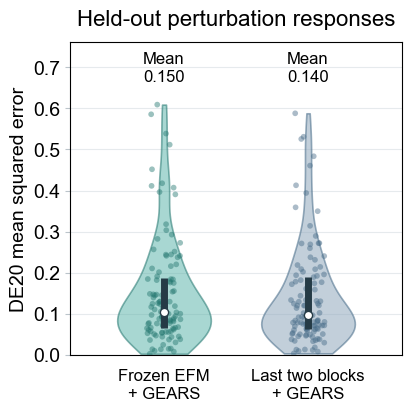

In [9]:
colors = ["#62B6AD", "#91A9BD"]
edge_colors = ["#23766F", "#456A87"]
fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
for position, (name, color, edge_color) in enumerate(
    zip(evaluations, colors, edge_colors)
):
    distances = evaluations[name].conditions["mse_de20"].to_numpy()
    violin = ax.violinplot(
        distances, positions=[position], widths=0.65,
        showmeans=False, showmedians=False, showextrema=False,
    )
    for body in violin["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(edge_color)
        body.set_alpha(0.55)
        body.set_linewidth(1.2)
    jitter = np.random.default_rng(42).uniform(-0.12, 0.12, len(distances))
    ax.scatter(position + jitter, distances, s=17, color=edge_color,
               alpha=0.45, edgecolors="none", zorder=3)
    q1, median, q3 = np.quantile(distances, [0.25, 0.5, 0.75])
    ax.vlines(position, q1, q3, color="#253B46", linewidth=5, zorder=4)
    ax.scatter(position, median, s=35, color="white", edgecolor="#253B46", zorder=5)
    ax.text(position, 0.97, f"Mean\n{distances.mean():.3f}",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=12)

ax.set_title("Held-out perturbation responses", fontsize=16, pad=12)
ax.set_ylabel("DE20 mean squared error", fontsize=14)
ax.set_xticks(range(2), ["Frozen EFM\n+ GEARS", "Last two blocks\n+ GEARS"], fontsize=12)
ax.set_xlim(-0.65, 1.65)
ax.set_ylim(0, max(result.conditions["mse_de20"].max() for result in evaluations.values()) * 1.25)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color="#E6EAED", linewidth=0.8)
ax.tick_params(axis="x", length=0, pad=10)
ax.tick_params(axis="y", color="#BBC4CA", labelsize=14)
plt.show()


### Inspect a single and a double perturbation

DUSP9+ctrl and MAP2K6+SPI1 are fixed examples selected from the split before inspecting prediction scores. Each dot is one retained gene; teal highlights DE20 genes. The diagonal marks agreement. Every panel is 4×4 inches.


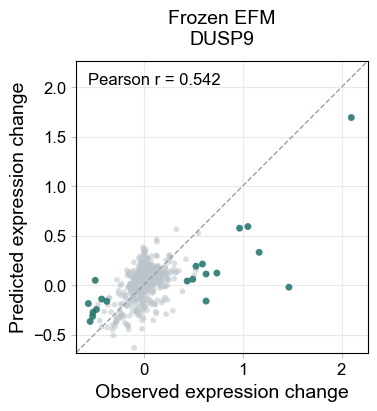

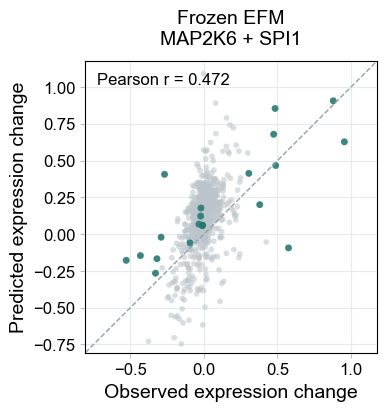

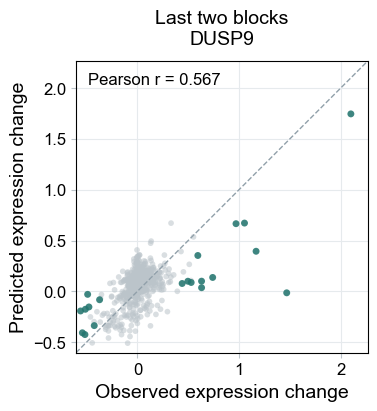

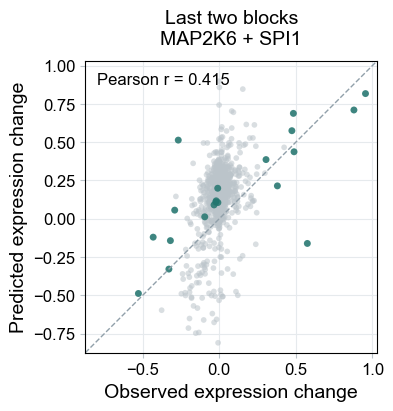

In [10]:
for method, prediction in predictions.items():
    for condition in ["DUSP9+ctrl", "MAP2K6+SPI1"]:
        observed = np.asarray(test[test.obs["condition"] == condition].X.mean(axis=0)).ravel()
        observed_delta = observed - control_mean
        predicted_delta = prediction.mean_expression.loc[condition].to_numpy() - control_mean
        de_positions = train.var_names.get_indexer(de_genes[condition])
        fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
        ax.scatter(observed_delta, predicted_delta, s=17, color="#BBC4CA",
                   alpha=0.55, edgecolors="none")
        ax.scatter(observed_delta[de_positions], predicted_delta[de_positions],
                   s=25, color="#23766F", alpha=0.85, edgecolors="none")
        limits = np.array([
            min(observed_delta.min(), predicted_delta.min()),
            max(observed_delta.max(), predicted_delta.max()),
        ]) * 1.08
        ax.plot(limits, limits, color="#91A0AA", linewidth=1, linestyle="--")
        ax.set_xlim(limits)
        ax.set_ylim(limits)
        ax.set_aspect("equal", adjustable="box")
        correlation = evaluations[method].conditions.loc[condition, "pearson_delta"]
        ax.text(0.04, 0.96, f"Pearson r = {correlation:.3f}",
                transform=ax.transAxes, ha="left", va="top", fontsize=12)
        label = "Frozen EFM" if method == "Frozen EFM + GEARS" else "Last two blocks"
        ax.set_title(label + "\n" + condition.replace("+ctrl", "").replace("+", " + "), fontsize=14, pad=12)
        ax.set_xlabel("Observed expression change", fontsize=14)
        ax.set_ylabel("Predicted expression change", fontsize=14)
        ax.tick_params(labelsize=12, color="#BBC4CA")
        ax.set_axisbelow(True)
        ax.grid(True, color="#E6EAED", linewidth=0.8)
        plt.show()


## 6. Optional: save the predictors and evaluation tables

Export is disabled by default. When enabled, this saves each selected predictor and its prediction and evaluation tables. Checkpoints retain the freezing policy, gene/ontology axes, tokenizer configuration and validation history. Figures remain inline.

Reload with `GenePerturbationPredictor.from_checkpoint(path, model_source=MODEL_SOURCE)`. Apply the same source expression scale and selected genes before prediction; checkpoint loading does not normalize raw data.

For long runs, `fit(training_checkpoint=...)` saves recovery state after each epoch. Use `resume_from=` with the same inputs and settings to continue training.

Recovery inputs include the learning-rate schedule and early-stopping patience; resume with the same settings.


In [11]:
SAVE_RESULTS = False
if SAVE_RESULTS:
    output_dir = REPO_ROOT / "results" / "gene_perturbation_tutorial"
    output_dir.mkdir(parents=True, exist_ok=True)
    frozen.save_checkpoint(output_dir / "frozen_efm_gears.pt")
    partial.save_checkpoint(output_dir / "partial_efm_gears.pt")
    with (output_dir / "group_metrics.csv").open("x") as handle:
        group_metrics.to_csv(handle)
    for name, stem in [
        ("Frozen EFM + GEARS", "frozen"),
        ("Partial Fine-tuning EFM + GEARS", "partial"),
    ]:
        with (output_dir / f"{stem}_predictions.csv").open("x") as handle:
            predictions[name].to_expression_table().to_csv(handle)
        with (output_dir / f"{stem}_per_condition.csv").open("x") as handle:
            evaluations[name].to_condition_table().to_csv(handle)


The decoder is adapted from [GEARS](https://github.com/snap-stanford/GEARS). The deliberate upstream extension is a separate contextual EFM gene representation for every control cell, inspired by [scFoundation](https://github.com/biomap-research/scFoundation/tree/main/GEARS). The adapted model source retains the complete GEARS copyright and MIT notice. Cite [Norman et al.](https://doi.org/10.1126/science.aax4438), [GSE133344](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE133344), GEARS and scCAFM.
